<a href="https://colab.research.google.com/github/nghialv108/vietnamese-foods-classification/blob/main/01_eda_30vnfoods.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("quandang/vietnamese-foods")

print("Path to dataset files:", path)

from pathlib import Path

print(Path(path).iterdir(),)

100%|██████████| 4.17G/4.17G [00:45<00:00, 99.4MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/quandang/vietnamese-foods/versions/11


**Import dữ liệu từ Kaggle
và in ra path**


In [ ]:
from pathlib import Path

dataset_root = Path(path)

for item in sorted(dataset_root.iterdir()):
    print(item.name, "| thư mục" if item.is_dir() else "| file")

inner = dataset_root / "Images"

for item in sorted(inner.iterdir()):
    print(item.name, "| thư mục" if item.is_dir() else "| file")

Images | thư mục
LICENSE | file
Urls | thư mục
Test | thư mục
Train | thư mục
Validate | thư mục


In [ ]:
from pathlib import Path

dataset_root = Path(path)

def show_tree(folder, depth=0, max_depth=2, max_items=6):
    items = sorted(folder.iterdir())
    for item in items[:max_items]:
        print("  " * depth + item.name + ("/" if item.is_dir() else ""))
        if item.is_dir() and depth < max_depth:
            show_tree(item, depth + 1, max_depth, max_items)
    if len(items) > max_items:
        print("  " * depth + f"... (còn {len(items) - max_items} mục nữa)")

show_tree(dataset_root)

Images/
  Test/
    Banh beo/
    Banh bot loc/
    Banh can/
    Banh canh/
    Banh chung/
    Banh cuon/
    ... (còn 24 mục nữa)
  Train/
    Banh beo/
    Banh bot loc/
    Banh can/
    Banh canh/
    Banh chung/
    Banh cuon/
    ... (còn 24 mục nữa)
  Validate/
    Banh beo/
    Banh bot loc/
    Banh can/
    Banh canh/
    Banh chung/
    Banh cuon/
    ... (còn 24 mục nữa)
LICENSE
Urls/
  Banh beo.txt
  Banh bot loc.txt
  Banh can.txt
  Banh canh.txt
  Banh chung.txt
  Banh cuon.txt
  ... (còn 24 mục nữa)


In [ ]:
import pandas as pd
from pathlib import Path

dataset_root = Path(path)

# Tìm thư mục chứa train/test/validation, kể cả khi nằm lồng bên trong
base = next(p.parent for p in dataset_root.rglob("*") if p.is_dir() and p.name.lower() == "train")
print("Thư mục gốc chứa các tập:", base)
print("Các mục ở đó:", sorted(p.name for p in base.iterdir()))

Thư mục gốc chứa các tập: /root/.cache/kagglehub/datasets/quandang/vietnamese-foods/versions/11/Images
Các mục ở đó: ['Test', 'Train', 'Validate']


In [ ]:
splits = {
    "train": base / "Train",
    "val":   base / "Validate",   # sửa nếu tên khác, ví dụ "val"
    "test":  base / "Test",
}

rows = []
for split_name, split_dir in splits.items():
    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        n = sum(1 for f in class_dir.iterdir() if f.is_file())
        rows.append({"split": split_name, "class": class_dir.name, "count": n})

df = pd.DataFrame(rows)
table = df.pivot(index="class", columns="split", values="count")
table["total"] = table.sum(axis=1)
print(table)
print()
print(table.sum())

split             test  train  val  total
class                                    
Banh beo           129    451   65    645
Banh bot loc       144    503   73    720
Banh can           149    520   75    744
Banh canh          193    674   97    964
Banh chung         102    354   50    506
Banh cuon          228    798  114   1140
Banh duc           133    463   66    662
Banh gio           129    448   64    641
Banh khot          167    584   84    835
Banh mi            268    935  133   1336
Banh pia            89    310   45    444
Banh tet           138    480   68    686
Banh trang nuong   159    556   80    795
Banh xeo           235    821  117   1173
Bun bo Hue         306   1071  153   1530
Bun dau mam tom    184    640   92    916
Bun mam            155    541   77    773
Bun rieu           231    805  115   1151
Bun thit nuong     150    522   75    747
Ca kho to          136    473   67    676
Canh chua          165    577   83    825
Cao lau            124    432   62

In [ ]:
names = {k: set(p.name for p in v.iterdir() if p.is_dir()) for k, v in splits.items()}
print("Train = Val:", names["train"] == names["val"])
print("Train = Test:", names["train"] == names["test"])
print("Số lớp:", len(names["train"]))

Train = Val: True
Train = Test: True
Số lớp: 30


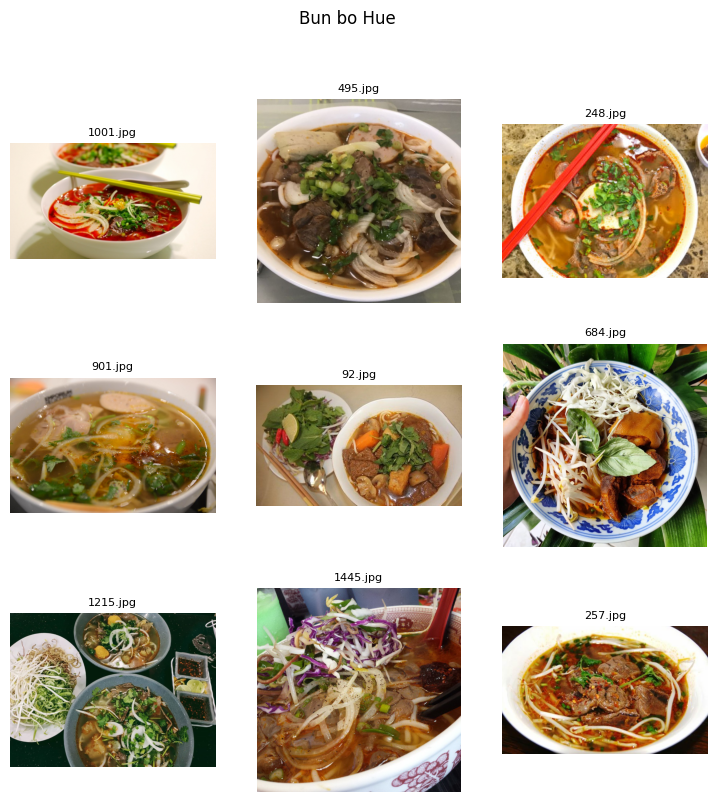

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

base = Path(path+"/Images")
splits = {"train": base/"Train", "val": base/"Validate", "test": base/"Test"}

cls = "Bun bo Hue"   # đổi tên món để xem món khác
files = random.sample(list((splits["train"]/cls).iterdir()), 9)

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for ax, f in zip(axes.ravel(), files):
    ax.imshow(Image.open(f).convert("RGB"))
    ax.set_title(f.name[:18], fontsize=8)
    ax.axis("off")
plt.suptitle(cls)
plt.show()

In [ ]:
import pandas as pd
from collections import Counter

bad, sizes, modes = [], [], Counter()

for split_name, d in splits.items():
    for f in d.rglob("*"):
        if f.is_file():
            try:
                with Image.open(f) as im:
                    im.load()
                    sizes.append((split_name, f.parent.name, im.width, im.height))
                    modes[im.mode] += 1
            except Exception as e:
                bad.append((str(f), repr(e)))

print("Số ảnh hỏng:", len(bad))
print(bad[:5])
print("Chế độ màu:", dict(modes))
sz = pd.DataFrame(sizes, columns=["split", "class", "w", "h"])
print(sz[["w", "h"]].describe())

Số ảnh hỏng: 0
[]
Chế độ màu: {'RGB': 25136}
                  w             h
count  25136.000000  25136.000000
mean     902.087524    780.859206
std      414.318880    413.946843
min      100.000000     83.000000
25%      640.000000    440.000000
50%     1000.000000    720.000000
75%     1080.000000   1080.000000
max     7360.000000   5616.000000


In [17]:
import hashlib
from collections import defaultdict

def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

groups = defaultdict(list)
for split_name, d in splits.items():
    for f in d.rglob("*"):
        if f.is_file():
            groups[md5(f)].append((split_name, f.parent.name, f.name))

dups = [v for v in groups.values() if len(v) > 1]
cross_split = [v for v in dups if len({s for s, _, _ in v}) > 1]
cross_label = [v for v in dups if len({c for _, c, _ in v}) > 1]

print("Nhóm ảnh trùng:", len(dups))
print("Trùng giữa các tập (nguy hiểm):", len(cross_split))
print("Trùng nhưng khác nhãn (sai nhãn):", len(cross_label))
print(cross_split[:3])

Nhóm ảnh trùng: 63
Trùng giữa các tập (nguy hiểm): 40
Trùng nhưng khác nhãn (sai nhãn): 38
[[('train', 'Banh can', '176.jpg'), ('val', 'Banh can', '177.jpg')], [('train', 'Banh can', '368.jpg'), ('test', 'Banh can', '369.jpg')], [('train', 'Banh can', '338.jpg'), ('val', 'Banh khot', '316.jpg')]]


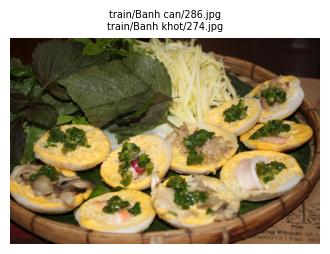

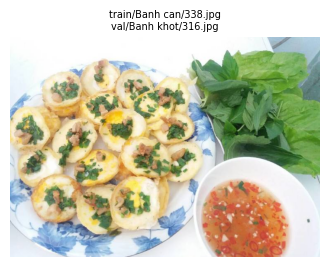

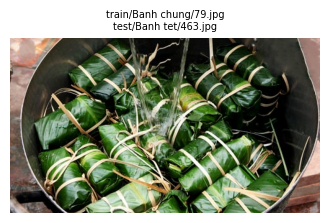

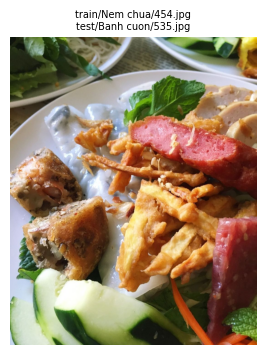

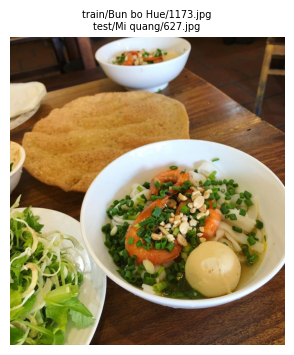

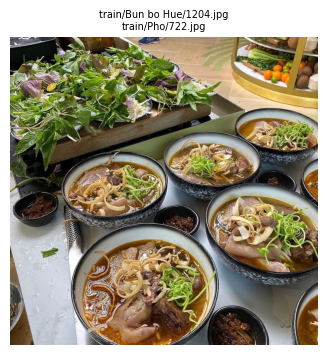

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

def show_group(g):
    fig, ax = plt.subplots(1, 1, figsize=(4, 4))
    s, c, n = g[0]
    ax.imshow(Image.open(splits[s] / c / n).convert("RGB"))
    ax.axis("off")
    ax.set_title("\n".join(f"{s}/{c}/{n}" for s, c, n in g), fontsize=7)
    plt.show()

for g in cross_label[:6]:
    show_group(g)

In [15]:
import pandas as pd

# Thứ tự ưu tiên giữ lại: train > val > test
priority = {"train": 0, "val": 1, "test": 2}

excluded = []
for g in dups:                       # g = list các bộ (tập, món, tên file)
    classes = {c for _, c, _ in g}

    if len(classes) > 1:
        # Cùng ảnh nhưng khác nhãn: loại TẤT CẢ bản sao
        for s, c, n in g:
            excluded.append((s, c, n, "khac nhan"))
    else:
        # Cùng nhãn: giữ đúng 1 bản (ưu tiên bản ở train), loại các bản còn lại
        g_sorted = sorted(g, key=lambda x: priority[x[0]])
        for s, c, n in g_sorted[1:]:
            excluded.append((s, c, n, "trung"))

excluded_df = pd.DataFrame(excluded, columns=["split", "class", "filename", "reason"])
print("Tổng số ảnh bị loại:", len(excluded_df))
print(excluded_df["reason"].value_counts())
print(excluded_df.groupby("split").size())

from google.colab import drive
drive.mount('/content/drive')

out_path = "/content/drive/MyDrive/vn_food_project/splits/excluded.csv"
excluded_df.to_csv(out_path, index=False)
print("Đã lưu:", out_path)


Tổng số ảnh bị loại: 104
reason
khac nhan    79
trung        25
Name: count, dtype: int64
split
test     36
train    54
val      14
dtype: int64
Mounted at /content/drive
Đã lưu: /content/drive/MyDrive/vn_food_project/splits/excluded.csv


In [16]:
excluded_keys = set(zip(excluded_df["split"], excluded_df["class"], excluded_df["filename"]))

clean = {}
for h, items in groups.items():
    kept = [x for x in items if x not in excluded_keys]
    if kept:
        clean[h] = kept

dups_after = [v for v in clean.values() if len(v) > 1]
cross_split_after = [v for v in dups_after if len({s for s, _, _ in v}) > 1]
cross_label_after = [v for v in dups_after if len({c for _, c, _ in v}) > 1]

print("Nhóm trùng còn lại:", len(dups_after))
print("Trùng giữa các tập:", len(cross_split_after))
print("Trùng khác nhãn:", len(cross_label_after))
print("Số ảnh còn lại:", sum(len(v) for v in clean.values()))

Nhóm trùng còn lại: 0
Trùng giữa các tập: 0
Trùng khác nhãn: 0
Số ảnh còn lại: 25032


## Tóm tắt EDA
- Tổng 25.136 ảnh, 30 lớp, chia sẵn 70/10/20 (train/val/test)
- Nhiều nhất: Bun bo Hue (1.530). Ít nhất: Banh pia (444). Chênh ~3,4 lần
- 0 ảnh hỏng, 100% RGB. Kích thước 100 đến 7360 px (rất không đồng đều)
- 63 nhóm ảnh trùng (MD5): 40 nhóm nằm ở nhiều tập, 38 nhóm khác nhãn
- Đã loại 104 ảnh (79 khác nhãn, 25 trùng), còn 25.032 ảnh. Danh sách ở excluded.csv
- Hạn chế: MD5 chỉ bắt ảnh giống từng byte
- Dự đoán cặp dễ nhầm: Pho và Bun bo Hue